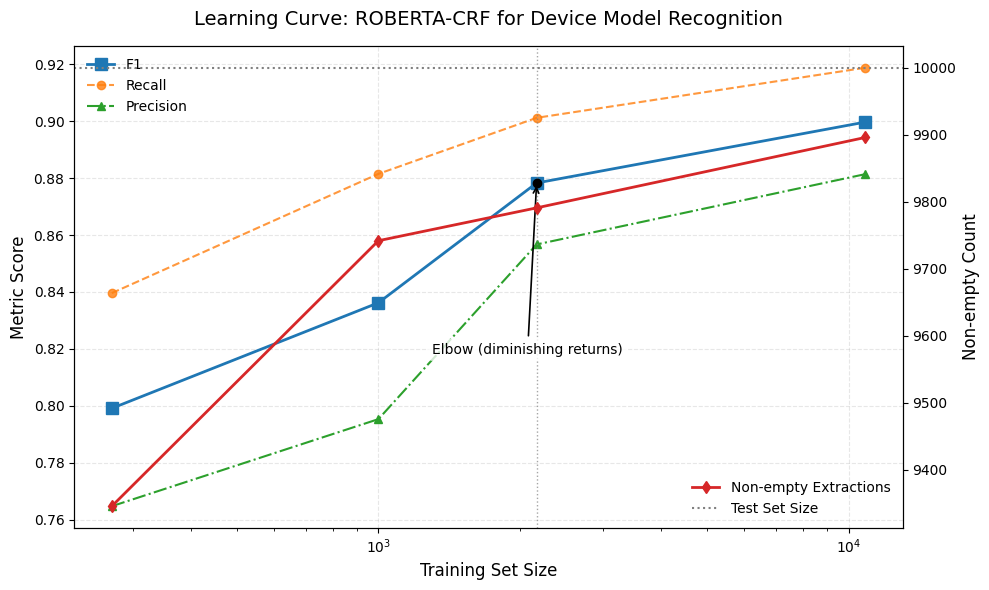

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# 数据配置
train_sizes = [271, 1000, 2170, 10847]  # 训练集样本量
f1_scores = [0.7991, 0.8362, 0.8783, 0.8997]  # F1值
recalls = [0.8396, 0.8815, 0.9012, 0.9188]  # 召回率
precisions = [0.7647, 0.7953, 0.8567, 0.8814]  # 精确率
non_empty = [9346, 9742, 9791, 9896]  # 非空提取数
test_set_total = 10000  # 测试集总量

# 创建双轴画布
fig, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()

# 性能指标曲线（主Y轴）
ax1.plot(train_sizes, f1_scores, 's-', color='#1f77b4', label='F1', lw=2, markersize=8)
ax1.plot(train_sizes, recalls, 'o--', color='#ff7f0e', label='Recall', alpha=0.8)
ax1.plot(train_sizes, precisions, '^-.', color='#2ca02c', label='Precision')

# 非空提取曲线（次Y轴）
ax2.plot(train_sizes, non_empty, 'd-', color='#d62728', label='Non-empty Extractions', lw=2)
ax2.axhline(y=test_set_total, color='gray', linestyle=':', label='Test Set Size')  # 测试集总量参考线

# 合理标注边际拐点：用 delta(F1) / delta(log(N)) 找增益下降最大的点
log_ns = np.log(train_sizes)
f1 = np.array(f1_scores)

# 计算每段的边际增益（以 log(N) 为分母）
if len(log_ns) >= 2:
    gains = np.diff(f1) / np.diff(log_ns)  # marginal gain per log-unit
else:
    gains = np.array([0.0])

# 找到增益下降最大的相对变化（若无明显下降则取最小增益处）
elbow_idx = 1
if len(gains) >= 2:
    rel_drop = (gains[:-1] - gains[1:]) / np.maximum(np.abs(gains[:-1]), 1e-8)
    max_drop_idx = int(np.argmax(rel_drop))
    if rel_drop[max_drop_idx] > 0:
        elbow_idx = max_drop_idx + 1
    else:
        elbow_idx = int(np.argmin(gains))
else:
    elbow_idx = 1

# 对应的坐标
x_elbow = train_sizes[elbow_idx]
y_elbow = f1_scores[elbow_idx]

# 标注与高亮
ax1.scatter([x_elbow], [y_elbow], color='black', zorder=5)
ax1.axvline(x=x_elbow, color='gray', linestyle=':', linewidth=1, alpha=0.7)
ax1.annotate('Elbow (diminishing returns)',
             xy=(x_elbow, y_elbow),
             xytext=(x_elbow * 0.6, y_elbow - 0.06),
             arrowprops=dict(arrowstyle="->", color='black', lw=1.2),
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="none", alpha=0.8))

# 坐标轴设置
ax1.set_xscale('log')  # 对数坐标突出小样本
ax1.set_xlabel("Training Set Size", fontsize=12)
ax1.set_ylabel("Metric Score", fontsize=12)
ax1.grid(alpha=0.3, linestyle='--')
ax2.set_ylabel("Non-empty Count", fontsize=12)

# 图例与标题
ax1.legend(loc='upper left', frameon=False)
ax2.legend(loc='lower right', frameon=False)
plt.title("Learning Curve: ROBERTA-CRF for Device Model Recognition", fontsize=14, pad=15)
plt.tight_layout()
plt.savefig('learning_curve.pdf', dpi=300)  # 矢量图输出

# 小模型生成结果置信度阈值设置

In [1]:
# 分析置信度统计分布
import jsonlines

samples = []
with jsonlines.open("OUTPUTs/final_llm_testset.jsonl", "r") as f:
    for sample in f:
        if sample.get("extracted_models"):
            samples.append(sample)

In [22]:
for sample in samples[:2]:
    print(sample['extracted_models'][0][1])
    print(sample['extracted_models'][0][0])

0.999347198009491
p1447-le
0.9992373883724213
ds-2cd2820f


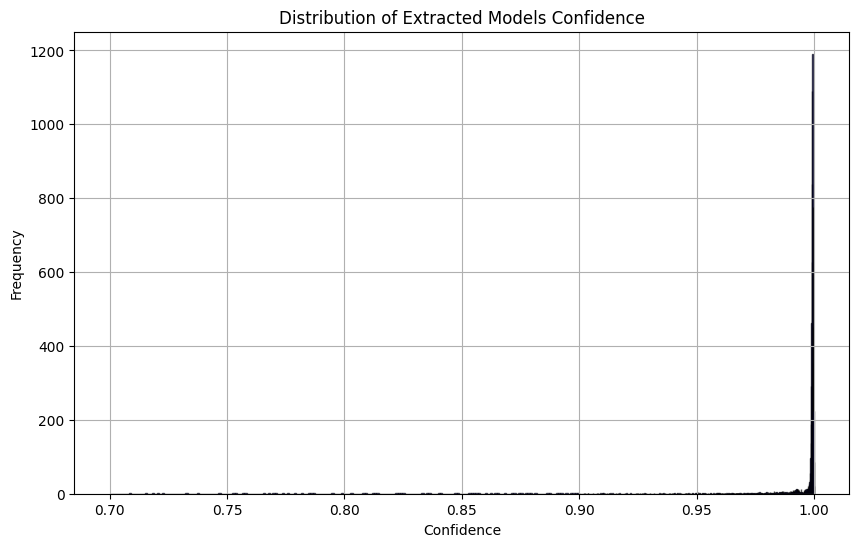

In [3]:
# ...existing code...

# 新增单元格：统计置信度分布和阈值准确率
import jsonlines
import matplotlib.pyplot as plt
import numpy as np

# 1. 统计置信度分布并绘制直方图
conf = [sample["extracted_models"][0][1] for sample in samples]

plt.figure(figsize=(10, 6))
bins = np.concatenate([np.linspace(0.7, 0.9, 200), np.linspace(0.9, 1.0, 1000)])
plt.hist(conf, bins=bins, alpha=0.7, color='blue', edgecolor='black')
plt.xlabel('Confidence')
plt.ylabel('Frequency')
plt.title('Distribution of Extracted Models Confidence')
plt.grid(True)
plt.show()

In [27]:
# 2. 计算阈值准确率
import re

def _norm_for_compare(s):
    if s is None:
        return ""
    s = str(s)
    # 移除所有空白、'-' 和 '/'，并小写化
    s = re.sub(r"[\s\-/]+", "", s).lower()
    return s

def calculate_accuracy_below_threshold(t):
    invoke_llm = 0
    incredible_samples = []
    for s in samples:
        if s["extracted_models"][0][1] < t:
            incredible_samples.append(s)
        else:
            invoke_llm += 1
    correct_count = sum(1 for s in incredible_samples if _norm_for_compare(s["extracted_models"][0][0]) == _norm_for_compare(s["product"]))
    accuracy = correct_count / len(incredible_samples) if incredible_samples else 0
    return accuracy, invoke_llm

# 示例：设置 t=0.90，计算准确率
t = 0.98
acc, invoke_llm = calculate_accuracy_below_threshold(t)
print(f"Threshold: {t}, Incredible Samples: {len([s for s in samples if s['extracted_models'][0][1] < t])}, Accuracy: {acc:.4f}")
print(f"Invoke LLM count: {invoke_llm}")

Threshold: 0.98, Incredible Samples: 400, Accuracy: 0.3650
Invoke LLM count: 8215


In [8]:
# 2. 计算阈值准确率
import re

def _norm_for_compare(s):
    if s is None:
        return ""
    s = str(s)
    # 移除所有空白、'-' 和 '/'，并小写化
    s = re.sub(r"[\s\-/]+", "", s).lower()
    return s

def calculate_accuracy_at_threshold(t):
    invoke_llm = 0
    credible_samples = []
    for s in samples:
        if s["extracted_models"][0][1] >= t:
            credible_samples.append(s)
        else:
            invoke_llm += 1
    correct_count = sum(1 for s in credible_samples if _norm_for_compare(s["extracted_models"][0][0]) == _norm_for_compare(s["model"]))
    accuracy = correct_count / len(credible_samples) if credible_samples else 0
    
    # 计算召回率：TP / (TP + FN)
    TP = correct_count
    FN = sum(1 for s in samples if s["extracted_models"][0][1] < t and _norm_for_compare(s["extracted_models"][0][0]) == _norm_for_compare(s["model"]))
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    
    return accuracy, invoke_llm, recall

# 示例：设置 t=0.965，计算准确率和召回率
t = 0.965
acc, invoke_llm, rec = calculate_accuracy_at_threshold(t)
print(f"Threshold: {t}, Credible Samples: {len([s for s in samples if s['extracted_models'][0][1] >= t])}, Accuracy: {acc:.4f}, Recall: {rec:.4f}")
print(f"Invoke LLM count: {invoke_llm}")

# 分层抽样后的10000条样本
t2 = 0.96
acc2, invoke_llm2, rec2 = calculate_accuracy_at_threshold(t2)
print(f"Threshold: {t2}, Credible Samples: {len([s for s in samples if s['extracted_models'][0][1] >= t2])}, Accuracy: {acc2:.4f}, Recall: {rec2:.4f}")
print(f"Invoke LLM count: {invoke_llm2}")

KeyError: 'model'

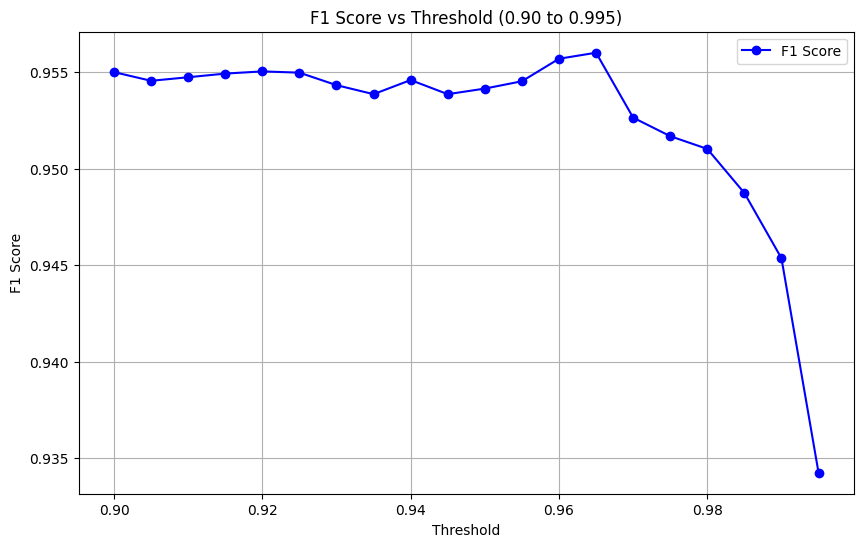

最大F1值: 0.9560, 对应的阈值t: 0.9650000000000001


In [70]:
# 绘制阈值从0.9到0.99时的F1值变化
import matplotlib.pyplot as plt
import numpy as np

thresholds = np.arange(0.90, 1.00, 0.005)  # 0.90, 0.91, ..., 0.99
f1_scores = []

for t in thresholds:
    acc, _, rec = calculate_accuracy_at_threshold(t)
    if acc + rec > 0:
        f1 = 2 * acc * rec / (acc + rec)
    else:
        f1 = 0
    f1_scores.append(f1)

plt.figure(figsize=(10, 6))
plt.plot(thresholds, f1_scores, marker='o', color='blue', label='F1 Score')
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 Score vs Threshold (0.90 to 0.995)')
plt.grid(True)
plt.legend()
plt.show()

# 输出F1的最大值和对应的阈值
max_f1 = np.max(f1_scores)
max_idx = np.argmax(f1_scores)
best_threshold = thresholds[max_idx]
print(f"最大F1值: {max_f1:.4f}, 对应的阈值t: {best_threshold}")

# SLM结果评估